# Lab 3-04：混合檢索——BM25 抓字面、向量抓語意，用 RRF 合起來

**目標**：在 Chroma 向量檢索旁邊加一路 BM25 關鍵字檢索，用 RRF 把兩份排名合成一份，用題庫比較三者。

**你會學到**
- 中文 BM25 要先斷詞；錯誤碼、指令要整個保留
- BM25 與向量各自的盲區：一個不懂換句話說，一個分不清 TP-4012 和 TP-4021
- RRF 只看名次不看分數，所以兩種尺度完全不同的分數也能合併
- 同一件事用 LlamaIndex 的 `QueryFusionRetriever` 怎麼做

**前置**：Lab 3-02、3-03。原理見 `00_concepts.md` 第 4 節。

**對應投影片**：「BM25 與向量的盲區」「混合檢索與重排」「RRF 怎麼算」「傳統 RAG 三痛點」

![兩份排名合成一份：RRF](images/rrf_merge.jpg)

*圖：左邊 BM25 和中間向量各自排出一份名單，RRF 不管原本的分數，只按名次給分（第 r 名得 1/(60+r)），兩份加總再排序。A 在兩份裡都很前面，所以合併後第一。*

## Step 1：準備兩路檢索的材料

同一批 chunk（依標題切＋補標題），一份進 Chroma，一份給 BM25。`allowed` 是現行文件的 chunk id，兩路都只在現行文件裡找。

In [1]:
from rag_utils import build_collection, chunk_docs, load_docs, load_qa

docs = load_docs()
qa = load_qa()
chunks = chunk_docs(docs)
text_of = {c.chunk_id: c.text for c in chunks}
collection = build_collection(chunks, "hybrid")

CURRENT = {"status": "current"}
allowed = {c.chunk_id for c in chunks if c.meta["status"] == "current"}
print(len(chunks), "塊，其中現行文件", len(allowed), "塊")

113 塊，其中現行文件 107 塊


## Step 2：中文要先斷詞

BM25 比的是「詞」有沒有出現。英文用空白切就好，中文沒有空白，要用斷詞工具 jieba。
但 jieba 不認得 `TP-4021`，會把它拆成 `TP`、`-`、`4021`，這樣 TP-4012 和 TP-4021 就共用了 `TP` 這個詞。

In [2]:
import jieba

query = "TP-4021 是什麼錯誤？可以重試嗎？"
print("jieba 直接切：", jieba.lcut(query))

jieba 直接切： ['TP', '-', '4021', ' ', '是', '什麼', '錯誤', '？', '可以', '重試', '嗎', '？']


`rag_utils.tokenize` 先用正規表達式把英數代碼整段抓出來，只把中文部分交給 jieba：

In [3]:
from rag_utils import tokenize

print("保留代碼：   ", tokenize(query))
print(tokenize("執行 hfctl tidepay failover --to acq-b，v3.4.0 改了冪等鍵"))

保留代碼：    ['tp-4021', '是', '什麼', '錯誤', '可以', '重試', '嗎']
['執行', 'hfctl', 'tidepay', 'failover', 'to', 'acq-b', 'v3.4.0', '改', '了', '冪', '等', '鍵']


## Step 3：用 `rank_bm25` 建索引

`BM25Okapi` 吃「斷好詞的文件清單」，查詢時對每份文件給一個分數。分數高低取決於：查詢詞有沒有出現、出現幾次、這個詞在全部文件裡稀不稀有（越稀有越值錢）。

In [4]:
from rank_bm25 import BM25Okapi

corpus_ids = [c.chunk_id for c in chunks]
bm25 = BM25Okapi([tokenize(c.text) for c in chunks])

scores = bm25.get_scores(tokenize(query))
top = sorted(range(len(scores)), key=lambda i: -scores[i])[:5]
for i in top:
    print(f"{scores[i]:6.2f}  {corpus_ids[i]}")

  9.90  rb-tp-4012-3ds-timeout#3
  7.90  svc-tidepay#3
  5.59  svc-breakwater#4
  5.02  svc-gull-notify#3
  4.86  pm-2026-0921-mq-lag#2


點一下內部：`idf` 是每個詞的稀有度。`tp-4021` 只出現在少數幾塊，分數很高；「錯誤」到處都有，幾乎不加分。

In [5]:
for term in ["tp-4021", "tp-4012", "錯誤", "重試", "的"]:
    print(f"{term:<8} idf = {bm25.idf.get(term, 0):.2f}")

tp-4021  idf = 3.80
tp-4012  idf = 2.81
錯誤       idf = 1.85
重試       idf = 2.65
的        idf = 0.96


`rag_utils.BM25Index` 就是上面三行包起來，多一個 `allowed` 參數只回傳現行文件。

In [6]:
from rag_utils import BM25Index, vector_search

bm25_index = BM25Index(chunks)
print(bm25_index.search(query, k=5, allowed=allowed))

['rb-tp-4012-3ds-timeout#3', 'svc-tidepay#3', 'svc-breakwater#4', 'svc-gull-notify#3', 'pm-2026-0921-mq-lag#2']


## Step 4：兩路各自的盲區

兩種問題各挑一題，看前 5 名：
- 關鍵字題：問題只有代碼，向量容易被「長得很像」的代碼騙。
- 語意題：問題用口語描述，文件裡沒有一樣的字，BM25 找不到。

In [7]:
probes = {
    "關鍵字題": "BW-504 是什麼？",
    "語意題": "新版上線後發現有問題，要怎麼退回舊版？需要誰同意？",
}
for kind, q in probes.items():
    print(f"【{kind}】{q}")
    print("  BM25：", bm25_index.search(q, 5, allowed))
    print("  向量：", vector_search(collection, q, 5, CURRENT))

【關鍵字題】BW-504 是什麼？
  BM25： ['svc-breakwater#4', 'svc-sandbar-dw#0', 'svc-reef-search#0', 'svc-current-mq#0', 'svc-breakwater#0']
  向量： ['rb-bw-503-circuit#1', 'svc-breakwater#4', 'rb-bw-503-circuit#3', 'rb-bw-503-circuit#0', 'svc-breakwater#1']
【語意題】新版上線後發現有問題，要怎麼退回舊版？需要誰同意？
  BM25： ['faq-oncall#0', 'faq-prod-access#1', 'faq-deploy#1', 'policy-data-retention#2', 'faq-deploy#2']
  向量： ['faq-deploy#2', 'svc-anchor-order#4', 'faq-deploy#3', 'svc-lighthouse-auth#3', 'pm-2026-0607-auth-outage#3']


答案分別在 `svc-breakwater`（錯誤碼表）與 `faq-deploy`（回滾）。看哪一路把它們排在前面、哪一路漏掉。

## Step 5：RRF——只看名次

BM25 分數可以是 0～30，cosine 是 0～1，直接相加沒有意義。RRF 的做法：每一路的第 r 名得 1/(60+r) 分，加總後排序。
60 是原論文的常數，讓第 1 名和第 10 名的差距不要太懸殊。

這段只有 5 行，而且 `rank_bm25` 和 Chroma 都沒有提供「跟別人合併」的功能，所以自己寫；寫出來也最容易看懂。

In [8]:
def rrf(rankings: list[list[str]], k: int = 60) -> list[str]:
    scores: dict[str, float] = {}
    for ranking in rankings:
        for rank, cid in enumerate(ranking, start=1):
            scores[cid] = scores.get(cid, 0.0) + 1.0 / (k + rank)
    return sorted(scores, key=lambda c: -scores[c])

拆開看一題的計分：每一塊在兩路各排第幾、各得多少分。

In [9]:
q = probes["關鍵字題"]
bm_rank = bm25_index.search(q, 10, allowed)
vec_rank = vector_search(collection, q, 10, CURRENT)
fused = rrf([bm_rank, vec_rank])

print(f"{'chunk':<30}{'BM25名次':>8}{'向量名次':>8}{'RRF 分數':>10}")
for cid in fused[:6]:
    rb = bm_rank.index(cid) + 1 if cid in bm_rank else None
    rv = vec_rank.index(cid) + 1 if cid in vec_rank else None
    score = (1 / (60 + rb) if rb else 0) + (1 / (60 + rv) if rv else 0)
    print(f"{cid:<30}{str(rb or '-'):>8}{str(rv or '-'):>8}{score:>10.4f}")

chunk                           BM25名次    向量名次    RRF 分數
svc-breakwater#4                     1       2    0.0325
rb-bw-503-circuit#1                  -       1    0.0164
svc-sandbar-dw#0                     2       -    0.0161
svc-reef-search#0                    3       -    0.0159
rb-bw-503-circuit#3                  -       3    0.0159
svc-current-mq#0                     4       -    0.0156


## Step 6：三種檢索跑完整份題庫

同樣用 Hit@1、Hit@3、MRR（Lab 3-03 介紹過），並且把關鍵字題和語意題分開算。

In [10]:
import numpy as np

from rag_utils import dedup_docs, hit_at_k, reciprocal_rank

retrievers = {
    "BM25": lambda q: bm25_index.search(q, 10, allowed),
    "向量": lambda q: vector_search(collection, q, 10, CURRENT),
    "混合 RRF": lambda q: rrf([bm25_index.search(q, 10, allowed), vector_search(collection, q, 10, CURRENT)]),
}

rows = []  # (方法, 題型, Hit@1, Hit@3, RR)
for name, fn in retrievers.items():
    for q in qa:
        ranked = dedup_docs(fn(q["question"]))
        rows.append((name, q["type"], hit_at_k(ranked, q["doc_ids"], 1),
                     hit_at_k(ranked, q["doc_ids"], 3), reciprocal_rank(ranked, q["doc_ids"])))

import pandas as pd

df = pd.DataFrame(rows, columns=["方法", "題型", "Hit@1", "Hit@3", "MRR"])
summary = df.groupby("方法")[["Hit@1", "Hit@3", "MRR"]].mean().loc[list(retrievers)]
by_type = df.pivot_table(index="方法", columns="題型", values="Hit@1").loc[list(retrievers)]
print(summary.round(2))
print()
print("Hit@1 依題型：")
print(by_type.round(2))

        Hit@1  Hit@3   MRR
方法                        
BM25     0.82   0.95  0.87
向量       0.89   1.00  0.95
混合 RRF   0.92   0.97  0.95

Hit@1 依題型：
題型      keyword  semantic
方法                       
BM25       0.91      0.67
向量         0.83      1.00
混合 RRF     0.96      0.87


## Step 7：畫出來

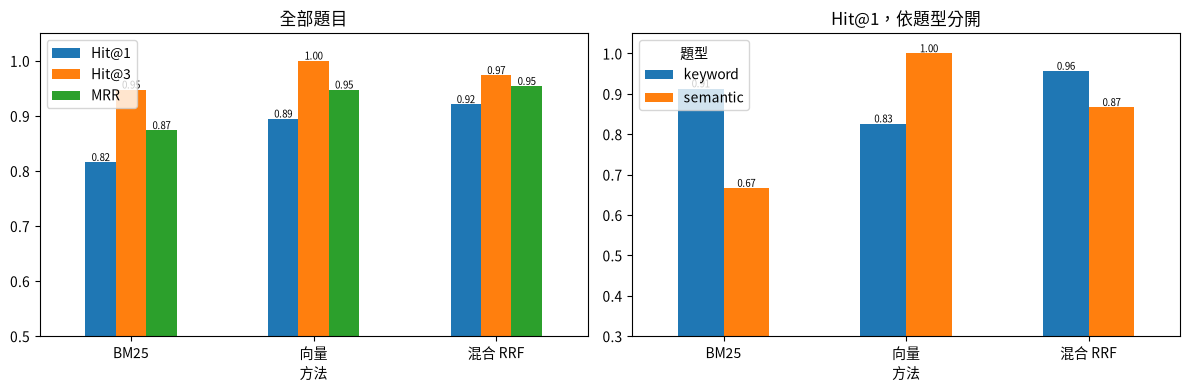

In [11]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
summary.plot.bar(ax=axes[0], rot=0, ylim=(0.5, 1.05), title="全部題目")
by_type.plot.bar(ax=axes[1], rot=0, ylim=(0.3, 1.05), title="Hit@1，依題型分開")
for ax in axes:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=7)
plt.tight_layout()
plt.show()

讀圖重點：BM25 在語意題吃虧，向量在關鍵字題吃虧，RRF 把兩邊的長處拉在一起。
RRF 不保證每一題都比單一路好——兩路都排錯時它也救不回來；它換來的是**比較少大翻車**。
剩下的錯誤留給下一本的重排序模型。

## Step 8：哪些題目被 RRF 救回來？

In [12]:
pivot = df.pivot_table(index=df.index % len(qa), columns="方法", values="Hit@1")
for i, q in enumerate(qa):
    r = pivot.loc[i]
    if r["混合 RRF"] != r["向量"] or r["混合 RRF"] != r["BM25"]:
        mark = lambda v: "對" if v else "錯"
        print(f"{q['id']} {q['question'][:24]:<26} BM25:{mark(r['BM25'])} 向量:{mark(r['向量'])} RRF:{mark(r['混合 RRF'])}")

q05 NTF-602 代表什麼？怎麼處理？         BM25:錯 向量:對 RRF:對
q13 哪一張測試信用卡會觸發 3D 驗證逾時？       BM25:對 向量:錯 RRF:對
q16 使用者付款時一直被扣兩次錢，以前發生過嗎？原因是   BM25:錯 向量:對 RRF:錯
q18 出貨通知寄得很慢，要怎麼加速消化積壓的訊息？     BM25:錯 向量:對 RRF:對
q19 什麼時間可以把新版本推上正式環境？          BM25:錯 向量:對 RRF:對
q21 新版上線後發現有問題，要怎麼退回舊版？需要誰同意   BM25:錯 向量:對 RRF:對
q30 資料倉儲裡的手機號碼會怎麼顯示？           BM25:錯 向量:對 RRF:錯
q31 BW-504 是什麼？                BM25:對 向量:錯 RRF:對
q38 hfctl gw breaker reset 什   BM25:對 向量:錯 RRF:對


## Step 9：LlamaIndex 版——`QueryFusionRetriever`

LlamaIndex 內建「多路檢索＋融合」：把幾個 retriever 交給 `QueryFusionRetriever`，`mode="reciprocal_rerank"` 就是 RRF。
我們的兩路（Chroma、rank_bm25）不是 LlamaIndex 原生的，所以各寫一個小 `BaseRetriever`：只要實作 `_retrieve`，回傳 `NodeWithScore` 清單。
這是 LlamaIndex 最常用的擴充點，Lab 3-07 還會再用到。

In [13]:
from llama_index.core.retrievers import BaseRetriever, QueryFusionRetriever
from llama_index.core.schema import NodeWithScore, TextNode


class ChromaRetriever(BaseRetriever):
    def __init__(self, k: int = 10):
        self.k = k
        super().__init__()

    def _retrieve(self, query_bundle):
        res = collection.query(query_texts=[query_bundle.query_str], n_results=self.k, where=CURRENT)
        return [NodeWithScore(node=TextNode(id_=cid, text=doc), score=1 - dist)
                for cid, doc, dist in zip(res["ids"][0], res["documents"][0], res["distances"][0])]


class BM25Retriever(BaseRetriever):
    def __init__(self, k: int = 10):
        self.k = k
        super().__init__()

    def _retrieve(self, query_bundle):
        return [NodeWithScore(node=TextNode(id_=cid, text=text_of[cid]), score=1.0)
                for cid in bm25_index.search(query_bundle.query_str, self.k, allowed)]

`num_queries=1` 表示不讓 LLM 改寫問題（改寫是下一本的主題），只做融合。`llm` 參數仍然要給，因為它預設會去找 OpenAI。

In [14]:
from llama_index.llms.openai_like import OpenAILike

llm = OpenAILike(api_base="http://localhost:11434/v1", api_key="ollama", model="qwen2.5:3b", is_chat_model=True)
fusion = QueryFusionRetriever(
    [BM25Retriever(), ChromaRetriever()],
    llm=llm, mode="reciprocal_rerank", num_queries=1, similarity_top_k=10, use_async=False,
)

for node in fusion.retrieve(probes["關鍵字題"])[:5]:
    print(f"{node.score:.4f}  {node.node.node_id}")

0.0331  svc-breakwater#4
0.0167  rb-bw-503-circuit#1
0.0164  svc-sandbar-dw#0
0.0161  svc-reef-search#0
0.0161  rb-bw-503-circuit#3


跟自己寫的 RRF 對答案：整份題庫的前 10 名是否完全一樣？

In [15]:
same = sum(
    [n.node.node_id for n in fusion.retrieve(q["question"])] == retrievers["混合 RRF"](q["question"])[:10]
    for q in qa
)
print(f"{same} / {len(qa)} 題的前 10 名完全相同")

38 / 38 題的前 10 名完全相同


排名完全一樣，分數卻略大一點：LlamaIndex 的名次從 0 起算（第一名得 1/60），我們從 1 起算（1/61）。只看名次的方法，這種差別不影響結果。
自己寫 5 行與用框架，結果相同；差別在於框架版可以直接接上 LlamaIndex 的 query engine、重排序器與 LLM 改寫。

## 試試看

1. 把 RRF 的常數 60 改成 1 和 1000，重跑 Step 6。常數越小，第 1 名的優勢越大，結果怎麼變？
2. 給兩路加權重：BM25 的貢獻乘 0.5、向量乘 1.5。哪種題型受影響最大？
3. 在 `tokenize` 裡把「代碼整段保留」拿掉（直接 `jieba.lcut`），重跑 BM25，關鍵字題的 Hit@1 掉多少？

## 小結

- BM25 抓字面（錯誤碼、指令、版本號），向量抓語意（換句話說）；各自有盲區。
- RRF 只用名次合併，不用調分數尺度，5 行就寫得完；LlamaIndex 的 `QueryFusionRetriever(mode="reciprocal_rerank")` 結果相同，而且能接自訂 retriever。
- 混合檢索負責「撈得到」（召回），排序還不夠準。下一本 Lab 3-05 用 cross-encoder 重排序，並試試查詢改寫與 small-to-big。